# **Text Representation Techniques for RAG Systems**

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# 📖 TABLE OF CONTENTS

- [Setup](#Setup)
- [Introduction to Text Representation: Bag-of-Words Model](#Introduction-to-Text-Representation:-Bag-of-Words-Model)
  - [Introduction](#Introduction)
  - [Why Text Representation is Essential](#Why-Text-Representation-is-Essential)
  - [Understanding BOW Model](#Understanding-BOW-Model)
  - [Building a Basic Vocabulary](#Building-a-Basic-Vocabulary)
  - [Converting Text to Vectors](#Converting-Text-to-Vectors)
  - [Conclusion and Next Steps](#Conclusion-and-Next-Steps)
  - [Text Cleaning with Python](#Text-Cleaning-with-Python)
  - [Building a Vocabulary Dictionary](#Building-a-Vocabulary-Dictionary)
  - [Transform Text into Numeric Vectors](#Transform-Text-into-Numeric-Vectors)
- [Generating and Comparing Sentence Embeddings](#Generating-and-Comparing-Sentence-Embeddings)
  - [Introduction](#Introduction)
  - [Understanding Sentence Embeddings](#Understanding-Sentence-Embeddings)
  - [Understanding the Cosine Similarity Function](#Understanding-the-Cosine-Similarity-Function)
  - [Loading the Sentence Transformers Library](#Loading-the-Sentence-Transformers-Library)
  - [Encoding Sentences into Embeddings](#Encoding-Sentences-into-Embeddings)
  - [Comparing Sentence Embeddings with Cosine Similarity](#Comparing-Sentence-Embeddings-with-Cosine-Similarity)
  - [Finding the Most Similar Sentences](#Finding-the-Most-Similar-Sentences)
  - [Exploring Sentence Similarity Changes](#Exploring-Sentence-Similarity-Changes)
  - [Ranking Sentences by Similarity](#Ranking-Sentences-by-Similarity)
  - [Conclusion and Next Steps](#Conclusion-and-Next-Steps)
- [Visualizing Sentence Embeddings with t-SNE](#Visualizing-Sentence-Embeddings-with-t-SNE)
  - [Introduction](#Introduction)
  - [Understanding t-SNE](#Understanding-t-SNE)
  - [Building Our Data](#Building-Our-Data)
  - [Generating and Reducing Embeddings](#Generating-and-Reducing-Embeddings)
  - [Plotting the Embeddings](#Plotting-the-Embeddings)
  - [Interpreting the t-SNE Plot](#Interpreting-the-t-SNE-Plot)
  - [Adding a New Category](#Adding-a-New-Category)
  - [Conclusion and Next Steps](#Conclusion-and-Next-Steps)
- [Comparing Bag-of-Words and Embeddings-Based Semantic Search](#Comparing-Bag-of-Words-and-Embeddings-Based-Semantic-Search)
  - [Introduction](#Introduction)
  - [From Words To Meaning: Why We Need Both Approaches](#From-Words-To-Meaning:-Why-We-Need-Both-Approaches)
  - [Implementing Bag-of-Words Search](#Implementing-Bag-of-Words-Search)
  - [Implementing Embedding-based Search](#Implementing-Embedding-based-Search)
  - [Bag-of-Words Search vs Embedding-based Search](#Bag-of-Words-Search-vs-Embedding-based-Search)
  - [Analyzing the Search Output](#Analyzing-the-Search-Output)
  - [Enhance Bag-of-Words with Bigrams](#Enhance-Bag-of-Words-with-Bigrams)
  - [Conclusion and Next Steps](#Conclusion-and-Next-Steps)
- [References](#References)

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# Setup

Before we jump in, let's quickly run the setup cell. It checks the environment (GPU, library versions) and sets random seeds for reproducibility — we want identical results on every run.

In [ ]:
# 🔧 Setup: Run this cell first!
# Environment check + random seeds for reproducibility

import sys
import time
import random
import numpy as np
import pandas as pd
import matplotlib as mpl
import torch
import torch.nn as nn

print(f"📦 Python       {sys.version.split()[0]}")
print(f"🔢 NumPy        {np.__version__}")
print(f"🐼 Pandas       {pd.__version__}")
print(f"📊 Matplotlib   {mpl.__version__}")
print(f"🔥 PyTorch      {torch.__version__}")

# GPU check (only needed for optional deep-feature experiments)
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"✅ GPU available: {torch.cuda.get_device_name(0)}")
    print(f"   Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    device = torch.device("cpu")
    print("⚠️ No GPU detected")

DEVICE_LABEL = "GPU" if device.type == "cuda" else "CPU"

# Random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"\n🎲 Random seed set to {SEED} (Python, NumPy, PyTorch)")

%matplotlib inline
%config InlineBackend.figure_format = 'jpeg'   # photos as JPEG, not PNG — ~10× smaller notebook
# Remove character limits for all columns of Pandas dataframes permanently in this session
pd.set_option('display.max_colwidth', None)

📦 Python       3.9.6
🔢 NumPy        2.0.2
🐼 Pandas       2.3.3
📊 Matplotlib   3.9.4
🔥 PyTorch      2.8.0
⚠️ No GPU detected

🎲 Random seed set to 42 (Python, NumPy, PyTorch)


![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# Introduction to Text Representation: Bag-of-Words Model

## Introduction

Welcome to the very first lesson of our course "**Text Representation Techniques for RAG Systems**", part of our "**Foundations of RAG Systems**" course path! In the first course of this learning path, you learned the fundamentals of **RAG**, how to structure a simple **RAG workflow**, and why combining retrieval with generation is so powerful. Now, we'll shift our focus to how we can turn raw text into numerical data — a crucial step if we want our RAG systems to retrieve information accurately and feed it into downstream pipelines; in other words, we'll focus on the **indexing** component of our RAG pipeline.

In this lesson, our main objectives are:
1. Understand why we must transform text into a structured format for RAG workflows.
2. Explore the **Bag-of-Words (BOW)** method, a simple yet classic text representation technique.

By the end, you'll know how words get mapped into vectors and why these representations matter when building robust retrieval systems.

## Why Text Representation is Essential

RAG systems revolve around retrieving relevant documents based on a user’s query, then generating a final answer. However, computers don’t process language the way humans do; they require structured or numerical forms of text to effectively compare one document with another. Without a proper representation of text, two main issues arise:

* We *can’t reliably measure how similar* one piece of text is to another.
* It becomes far more difficult to retrieve accurate, *contextually relevant* information.

A straightforward solution to this challenge is the Bag-of-Words method. It works by counting how often each word appears, providing a simple numerical snapshot of a document. While this approach ignores the order of words and misses linguistic nuances, it’s an excellent entry point for understanding how to convert messy human language into machine-friendly formats that form the core of RAG systems.

## Understanding BOW Model

Let’s explore how Bag-of-Words vectors capture word frequency without considering word order. Consider these three sentences:

1. “I love machine learning”
2. “Machine learning is fun”
3. “I love coding”

To construct our BOW representation, we first gather all unique words to form our vocabulary: `{I, love, machine, learning, is, fun, coding}`. Each word in the vocabulary maps to an index:

| Word  | I   | love | machine | learning | is  | fun | coding |
| :---- | :-: | :--: | :-----: | :------: | :-: | :-: | :----: |
| Index | 0   | 1    | 2       | 3        | 4   | 5   | 6      |

With this vocabulary, we can transform each sentence into a numeric vector by counting the occurrences of each word. For example:


| Sentence | I   | love | machine | learning | is  | fun | coding |
| :------- | :-: | :--: | :-----: | :------: | :-: | :-: | :----: |
| I love machine learning | 1 | 1 | 1 | 1 | 0 | 0 | 0 |
| Machine learning is fun | 0 | 0 | 1 | 1 | 1 | 1 | 0 |
| I love coding | 1 | 1 | 0 | 0 | 0 | 0 | 1 |

In these vectors, each column corresponds to a word in the vocabulary, and the numbers indicate how often each word appears in the sentence. This frequency-based representation is a straightforward way to convert text into numerical form for retrieval tasks, providing a foundational understanding of text representation.

## Building a Basic Vocabulary

In a BOW approach, the first step is constructing a dictionary (often called a “vocabulary”) that assigns each distinct word an integer index. Here's how you might do it using a function that takes as input a collection of documents:

In [ ]:
def build_vocab(docs):
    unique_words = set()
    for doc in docs:
        for word in doc.lower().split():
            # Strip punctuation around words (simple approach)
            clean_word = word.strip(".,?!")
            if clean_word:
                unique_words.add(clean_word)
    # Sort the unique_words to have a consistent, deterministic order
    return {word: idx for idx, word in enumerate(sorted(unique_words))}

Let's see what's happening:

1. We iterate through each text in `docs`.
2. We convert the text to lowercase and split it into tokens (words).
3. We remove punctuation at the start and end of these tokens.
4. Each cleaned token is added to a `unique_words` set so we only keep distinct words.
5. Finally, we sort the collection of `unique words` to ensure a consistent order and assign each word an index stored in a dictionary.

This vocabulary allows us to look up a word and pinpoint exactly where it should appear in any BOW vector.

## Converting Text to Vectors

Once you have a vocabulary, you can create a numeric BOW vector for each text. Every position in the vector corresponds to one word in the vocabulary, and the vector entries indicate how many times each vocabulary word appears in the text. Let's illustrate with code:

In [ ]:
import numpy as np

def bow_vectorize(text, vocab):
    vector = np.zeros(len(vocab), dtype=int)
    for word in text.lower().split():
        clean_word = word.strip(".,?!")
        if clean_word in vocab:
            # Increment the vector slot corresponding to this word
            vector[vocab[clean_word]] += 1
    return vector

1. We create an `np` array of zeros, with the length equal to the number of unique words in our vocabulary.
2. For each cleaned token in our text, we look up its vocabulary index.
3. We increment the vector at that index, effectively counting the occurrences of each vocabulary word.

Even though BOW ignores word order and deeper linguistic information, it remains a valuable technique for smaller-scale tasks or as a baseline representation. It demonstrates the mechanics of transforming words into arrays of numerical counts, which is essential for retrieval tasks.

## Conclusion and Next Steps

In this lesson, you learned why text must be represented numerically for RAG systems and walked through a foundational technique — **Bag-of-Words** — to convert words into count-based vectors. While BOW has limitations in capturing context, it's an excellent first step in any NLP workflow. Practice building vocabularies and generating BOW vectors with your own text to get comfortable with these concepts.

Up next, we'll explore more advanced methods that preserve the sense and context of your text, such as embeddings derived from language models. In the practice exercises that follow, you'll get hands-on experience coding your own BOW pipeline.

This foundation will set the stage for more powerful semantic retrieval techniques and deeper integration with RAG pipelines later in the course. Good luck, and have fun experimenting!

## Text Cleaning with Python

You've just learned how to build a vocabulary and convert text into Bag-of-Words vectors. Now, let's put that knowledge into practice with a simple task.

Your objective is to create a function called `preprocess_string` that processes a single string. Here's what you need to do:

* Split the string into words.
* Convert each word to lowercase.
* Remove punctuation from the start and end of each word (bonus points for doing it with a list comprehension!).

This exercise will help you solidify your understanding of text preprocessing. Dive in and see how well you can clean up a string!

In [ ]:
def preprocess_string(text):
    # TODO: Split the text into words
    # TODO: Convert words to lowercase and remove punctuation
    # TODO: Return the cleaned tokens
    words = text.split()
    cleaned_words = [word.lower().strip(".,?!") for word in words]
    return cleaned_words

In [ ]:
print(preprocess_string("Hello, World! We are preprocessing strings today."))

['hello', 'world', 'we', 'are', 'preprocessing', 'strings', 'today']


## Building a Vocabulary Dictionary

Nice job on processing unique words and their counts! Now, let's take it a step further by creating a *vocabulary dictionary*.

Your task is to build a function that:

* Takes a list of tokens.
* Sorts these words.
* Assigns each word a numeric index to form a vocabulary dictionary.

This exercise will help you understand how to map words to indices, a key step in text representation. Dive in and see how well you can create a structured vocabulary!

In [ ]:
def preprocess_string(text):
    words = text.split()
    cleaned_tokens = [word.lower().strip(".,!?") for word in words]
    return cleaned_tokens


def build_vocab(tokens):
    # TODO: Sort the unique tokens and assign each a numeric index
    unique_tokens = set(tokens)
    return {token: idx for idx, token in enumerate(sorted(unique_tokens))}

In [ ]:
sentence = "Hello, World! We are preprocessing strings today."
tokens = preprocess_string(sentence)
vocab = build_vocab(tokens)
print(f'Vocabulary:\n{vocab}')

Vocabulary:
{'are': 0, 'hello': 1, 'preprocessing': 2, 'strings': 3, 'today': 4, 'we': 5, 'world': 6}


## Transform Text into Numeric Vectors

You've just explored how to build a vocabulary and convert text into *Bag-of-Words* vectors. Now, let's apply that knowledge in a practical task.

Your objective is to complete the `bow_vectorize` function. Here's what you need to do:

* Create a zero vector with the same length as the vocabulary.
* For each word in the text, clean it and check if it's in the vocabulary.
* Increment the vector slot corresponding to each vocabulary word found.

This exercise will help you solidify your understanding of transforming text into numeric vectors. Dive in and see how well you can implement this transformation!

In [ ]:
import numpy as np

def build_vocab(docs):
    unique_words = set()
    for doc in docs:
        for word in doc.lower().split():
            clean_word = word.strip(".,?!")
            if clean_word:
                unique_words.add(clean_word)
    return {word: idx for idx, word in enumerate(sorted(unique_words))}

def bow_vectorize(text, vocab):
    # TODO: Create a zero vector with the same length as the vocabulary
    # TODO: Convert the text to lowercase and split it into words
    # TODO: For each word, clean it by stripping punctuation
    # TODO: Check if the cleaned word is in the vocabulary
    # TODO: If the word is in the vocabulary, increment the corresponding index in the vector
    vector = np.zeros(len(vocab), dtype=int)
    for word in text.lower().split():
        clean_word = word.strip(".,?!")
        if clean_word in vocab:
            vector[vocab[clean_word]] += 1
    return vector

In [ ]:
example_texts = [
    "RAG stands for retrieval augmented generation, and retrieval is a key component of RAG.",
    "Data is crucial for retrieval processes, and without data, retrieval systems cannot function effectively."
]

vocab = build_vocab(example_texts)
print(f'Vocabulary:\n{vocab.items()}\n')

for text in example_texts:
    vector = bow_vectorize(text, vocab)
    print(f'Text: {text}\nBOW Vector: {vector}\n')

Vocabulary:
dict_items([('a', 0), ('and', 1), ('augmented', 2), ('cannot', 3), ('component', 4), ('crucial', 5), ('data', 6), ('effectively', 7), ('for', 8), ('function', 9), ('generation', 10), ('is', 11), ('key', 12), ('of', 13), ('processes', 14), ('rag', 15), ('retrieval', 16), ('stands', 17), ('systems', 18), ('without', 19)])

Text: RAG stands for retrieval augmented generation, and retrieval is a key component of RAG.
BOW Vector: [1 1 1 0 1 0 0 0 1 0 1 1 1 1 0 2 2 1 0 0]

Text: Data is crucial for retrieval processes, and without data, retrieval systems cannot function effectively.
BOW Vector: [0 1 0 1 0 1 2 1 1 1 0 1 0 0 1 0 2 0 1 1]



![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# Generating and Comparing Sentence Embeddings

## Introduction

Welcome back! This is the second lesson in our “**Text Representation Techniques for RAG Systems**” series. In our previous lesson, we introduced the **Bag-of-Words (BOW)** approach to converting text into numerical representations. Although BOW is intuitive and lays a solid foundation, it does not capture word order or deeper context.

Picture a helpdesk system that retrieves support tickets. Without a solid way to represent text contextually, customers searching for “account locked” might miss relevant entries labeled “login blocked” because the system can't recognize these phrases as related. This gap in understanding could lead to frustrated users and unresolved queries.

Today, we'll take a big step forward by learning to generate more expressive text embeddings — vectors that represent the semantic meaning of entire sentences. By the end of this lesson, you will know how to produce these embeddings and compare them with each other using *cosine similarity*.

## Understanding Sentence Embeddings

Imagine you have sentences scattered across a high-dimensional space, where each sentence is a point, and closeness in this space reflects semantic similarity. Unlike BOW — which only counts word occurrences — sentence embeddings capture the relationship between words, making similar sentences land near each other in this space. This powerful feature is vital for **Retrieval-Augmented Generation (RAG)** systems, where retrieving text that is closest in meaning to a query drives more accurate responses.

Sentence embeddings provide a more nuanced understanding of linguistic context, going beyond simple counts of word frequencies. For example, while a BOW model might treat the sentences "*I enjoy apples*" and "*He likes oranges*" as quite different, embeddings can capture that both sentences express a personal preference for fruit. This richer representation is especially helpful in complex applications such as semantic search, recommendation engines, and advanced conversational systems, where subtle differences in meaning can greatly impact the results.

## Understanding the Cosine Similarity Function

When we start turning words or sentences into vectors, we need a way to measure how similar they are. *Cosine similarity* is a standard approach that measures how aligned two vectors are by looking at the angle between them. In simple terms:

* A value of 1 indicates that the vectors point in exactly the same direction (maximally similar).
* A value of 0 means they're orthogonal (no shared direction).
* A value of -1 shows they point in completely opposite directions.

Mathematically, cosine similarity between vectors A and B is:

\begin{equation*}
\text{cosine similarity}(A, B) = \frac {A \cdot B}{\left\| A \right\| \left\| B \right\|}
\end{equation*}

where $A \cdot B$ is the dot product of $A$ and $B$, and $\left\| A \right\|$ and $\left\| B \right\|$ are the magnitudes (norms) of $A$ and $B$.

Translating this into code, using `numpy`:

In [ ]:
import numpy as np
from numpy.linalg import norm

def cosine_similarity(vec_a, vec_b):
    """
    Compute cosine similarity between two vectors.
    Range: -1 (opposite directions) to 1 (same direction).
    """
    return np.dot(vec_a, vec_b) / (norm(vec_a) * norm(vec_b))

Because cosine similarity is insensitive to overall vector magnitude, it's especially useful in measuring how close two sentence embeddings are in terms of meaning rather than raw length or counts. Moreover, in practical text-embedding scenarios embeddings are trained or normalized so that their cosine similarities typically stay between 0 and 1, indicating varying degrees of semantic closeness rather than exact opposites. This makes it an ideal choice for tasks like semantic search and document retrieval.

## Loading the Sentence Transformers Library

We will use a popular tool for embedding sentences: the [Sentence Transformers](https://github.com/huggingface/sentence-transformers) library. It allows us to quickly load pre-trained models that produce high-quality, semantically meaningful embeddings. These models are typically built on top of popular Transformer architectures like BERT or RoBERTa.

Below, we initialize a pre-trained model called `'sentence-transformers/all-MiniLM-L6-v2'`, known for producing compact, high-quality sentence embeddings:

In [ ]:
from sentence_transformers import SentenceTransformer

# Initialize a pre-trained embedding model from Sentence Transformers
model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

The `all-MiniLM-L6-v2` model is a compact variant of Microsoft's MiniLM. This model strikes a good balance between size and performance, making it especially useful for real-time or large-scale applications. Larger models from the `transformers` ecosystem may produce even more robust embeddings, but they can be more resource-intensive.

## Encoding Sentences into Embeddings

Now let's define some sentences, encode them into numerical vectors, and see what the resulting embeddings look like. This approach produces vectors that capture deeper semantic information compared to a BOW representation:

In [ ]:
sentences = [
    "RAG stands for Retrieval Augmented Generation.",
    "A Large Language Model is a Generative AI model for text generation.",
    "RAG enhance text generation of LLMs by incorporating external data",
    "Bananas are yellow fruits.",
    "Apples are good for your health.",
    "What's monkey's favorite food?"
]

embeddings = model.encode(sentences)
print(f'embeddings.shape: {embeddings.shape}')  # e.g., (6, 384), depending on the model
print(f'embeddings[o]:\n{embeddings[0]}')  # A sample embedding for the first sentence

embeddings.shape: (6, 384)
embeddings[o]:
[-1.11864559e-01  7.27333054e-02  1.31854806e-02 -1.21591520e-02
 -1.09949261e-01  3.22040431e-02  6.53926209e-02  2.80549023e-02
  9.90324304e-04 -4.80532981e-02  5.87489791e-02  3.41508500e-02
  4.78318073e-02 -7.20908493e-02 -7.90361762e-02  4.43398766e-02
  2.91630942e-02  1.10945202e-01 -4.54715965e-03  2.63817771e-03
 -4.45330329e-02  8.46416801e-02  1.75273195e-02 -3.06797121e-02
  2.60341056e-02  2.63756216e-02 -8.13348442e-02  4.55921469e-03
  1.59398600e-01  4.30705352e-03 -6.03301916e-03  9.03822780e-02
 -4.57265303e-02 -2.21017320e-02 -4.85288091e-02  3.69571857e-02
 -4.90494482e-02  7.59510994e-02  1.24898171e-02  3.49107049e-02
  2.91071218e-02 -3.67271970e-03  2.56012902e-02 -6.01953380e-02
  1.02029089e-02  2.63532568e-02 -2.77443342e-02 -5.00456942e-03
 -5.13048004e-03  1.94188245e-02  3.09097804e-02 -1.39860967e-02
  1.78055651e-02  5.07813208e-02 -2.74632405e-02 -1.56592820e-02
  6.10844344e-02 -8.06052983e-02 -3.48829553e-02

The `model.encode()` function transforms each sentence into a vector, where each dimension (e.g., 384 in this example) captures some aspect of its semantic meaning. This is in stark contrast to a BOW representation, where the dimensionality corresponds to the size of the vocabulary, and crucial contextual information (like word order) may be lost. The shape `(6, 384)` indicates that we have 6 sentence embeddings, each of length 384. This high-dimensional space helps cluster semantically similar sentences, even if their words differ.

## Comparing Sentence Embeddings with Cosine Similarity

Finally, let's compare sentences according to how similar they are. We can compute similarity scores for each pair of sentences using the `cosine_similarity` function introduced before:

In [ ]:
for i, sent_i in enumerate(sentences):
    for j, sent_j in enumerate(sentences[i+1:], start=i+1):
        similarity_score = cosine_similarity(embeddings[i], embeddings[j])
        print(f"Similarity('{sent_i}', '{sent_j}') = {similarity_score:.4f}")

Similarity('RAG stands for Retrieval Augmented Generation.', 'A Large Language Model is a Generative AI model for text generation.') = 0.1575
Similarity('RAG stands for Retrieval Augmented Generation.', 'RAG enhance text generation of LLMs by incorporating external data') = 0.4630
Similarity('RAG stands for Retrieval Augmented Generation.', 'Bananas are yellow fruits.') = 0.0550
Similarity('RAG stands for Retrieval Augmented Generation.', 'Apples are good for your health.') = 0.0399
Similarity('RAG stands for Retrieval Augmented Generation.', 'What's monkey's favorite food?') = -0.0126
Similarity('A Large Language Model is a Generative AI model for text generation.', 'RAG enhance text generation of LLMs by incorporating external data') = 0.4983
Similarity('A Large Language Model is a Generative AI model for text generation.', 'Bananas are yellow fruits.') = 0.0042
Similarity('A Large Language Model is a Generative AI model for text generation.', 'Apples are good for your health.') = 0.

Recall that larger similarity values indicate sentences that are more closely related in meaning. In these results, pairs referencing similar topics (e.g., RAG and LLMs, or apples and bananas) often produce higher similarity scores, while pairs referencing different topics yield lower scores. Notice how “`Bananas are yellow fruits.`” and “`What's monkey's favorite food?`” have no overlapping words yet still show a relatively high similarity, highlighting how embeddings capture semantic meaning more effectively than a simpler BOW model, which primarily relies on word overlap.

## Finding the Most Similar Sentences

Your task is to identify and print the pair of sentences with the highest cosine similarity from the given embeddings. This involves:

* Initializing variables to track the highest similarity score and the corresponding sentence pair.
* Iterating through each pair of sentences to compute their similarity.
* Updating the highest score and pair when a new maximum is found.
* Printing the most similar pair and their similarity score.

This exercise will help you automatically spot the most semantically related sentences. Keep up the good work!

In [ ]:
import numpy as np
from numpy.linalg import norm
from sentence_transformers import SentenceTransformer

def cosine_similarity(vec_a, vec_b):
    """
    Compute cosine similarity between two vectors:
    1 means identical direction, 0 means orthogonal.
    """
    return np.dot(vec_a, vec_b) / (norm(vec_a) * norm(vec_b))

# Load a pre-trained embedding model from Sentence Transformers
model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

# Example sentences
sentences = [
    "The Eiffel Tower is one of the most famous landmarks in Paris.",
    "Photosynthesis is the process by which plants convert sunlight into energy.",
    "The stock market experienced a significant drop last week.",
    "A balanced diet is essential for maintaining good health.",
    "The Louvre Museum in Paris houses the Mona Lisa painting."
]

# TODO: Find the pair of sentences with the highest similarity
embeddings = model.encode(sentences)
best_sim_score = None
best_sentence_pair = None
for i, sent_i in enumerate(sentences):
    for j, sent_j in enumerate(sentences[i+1:], start=i+1):
        sim_score = cosine_similarity(embeddings[i], embeddings[j])
        if best_sim_score is None or sim_score > best_sim_score:
            best_sim_score = sim_score
            best_sentence_pair = (sent_i, sent_j)

print(f"Similarity('{best_sentence_pair[0]}', '{best_sentence_pair[1]}') = {best_sim_score:.4f}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Similarity('The Eiffel Tower is one of the most famous landmarks in Paris.', 'The Louvre Museum in Paris houses the Mona Lisa painting.') = 0.3913


## Exploring Sentence Similarity Changes

Now, let’s make this exercise more challenging. Instead of adding a single contrasting sentence, add two new sentences to the existing list:
* One sentence that partially overlaps with the original three (i.e., it should be somewhat related to RAG/LLM topics).
* One sentence on a completely different topic.

After adding these sentences, run the code to observe how the similarity scores change when sentences introduce partial overlap versus an entirely unrelated topic.

In [ ]:
import numpy as np
from numpy.linalg import norm
from sentence_transformers import SentenceTransformer


def cosine_similarity(vec_a, vec_b):
    """
    Compute cosine similarity between two vectors:
    1 means identical direction, 0 means orthogonal.
    """
    return np.dot(vec_a, vec_b) / (norm(vec_a) * norm(vec_b))

# Load a pre-trained embedding model from Sentence Transformers
model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

# Example sentences with similar or related meaning
sentences = [
    "RAG stands for Retrieval Augmented Generation.",
    "A Large Language Model is a Generative AI model for text generation.",
    "RAG enhance text generation of LLMs by incorporating external data"
]

# TODO: Add two new sentences here:
# 1) one that partially overlaps with the first three
# 2) one that is completely different in topic
sentences.append("RAG grounds LLM responses on real documents.")
sentences.append("I want to visit Paris.")

# Encode each sentence into its embedding vector
embeddings = model.encode(sentences)

# Compare each sentence's embedding to every other using cosine similarity
for i, sent_i in enumerate(sentences):
    for j, sent_j in enumerate(sentences[i + 1:], start=i + 1):
        sim_score = cosine_similarity(embeddings[i], embeddings[j])
        print(f"Similarity('{sent_i}' , '{sent_j}') = {sim_score:.4f}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Similarity('RAG stands for Retrieval Augmented Generation.' , 'A Large Language Model is a Generative AI model for text generation.') = 0.1575
Similarity('RAG stands for Retrieval Augmented Generation.' , 'RAG enhance text generation of LLMs by incorporating external data') = 0.4630
Similarity('RAG stands for Retrieval Augmented Generation.' , 'RAG grounds LLM responses on real documents.') = 0.3564
Similarity('RAG stands for Retrieval Augmented Generation.' , 'I want to visit Paris.') = -0.0449
Similarity('A Large Language Model is a Generative AI model for text generation.' , 'RAG enhance text generation of LLMs by incorporating external data') = 0.4983
Similarity('A Large Language Model is a Generative AI model for text generation.' , 'RAG grounds LLM responses on real documents.') = 0.1588
Similarity('A Large Language Model is a Generative AI model for text generation.' , 'I want to visit Paris.') = 0.0417
Similarity('RAG enhance text generation of LLMs by incorporating external da

## Ranking Sentences by Similarity

You've done a great job exploring sentence similarity changes! Now, let's apply what you've learned in a practical scenario.

Your task is to:

* Select one sentence as a "query."
* Compute its similarity to each of the other three sentences.
* Print a ranking of these three sentences in descending order of similarity.

This exercise will help you understand how to use embeddings for simple retrieval tasks. Keep up the momentum and see how well you can rank the sentences!

In [ ]:
import numpy as np
from numpy.linalg import norm
from sentence_transformers import SentenceTransformer


def cosine_similarity(vec_a, vec_b):
    """
    Compute cosine similarity between two vectors:
    1 means identical direction, 0 means orthogonal.
    """
    return np.dot(vec_a, vec_b) / (norm(vec_a) * norm(vec_b))

# TODO: Load a pre-trained embedding model from Sentence Transformers
model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

# Example sentences
sentences = [
    "The Eiffel Tower is one of the most famous landmarks in Paris.",
    "Quantum computing promises to revolutionize technology with its speed.",
    "The Amazon rainforest is home to a vast diversity of wildlife.",
    "Meditation can significantly reduce stress and improve mental health.",
    "The Great Wall of China stretches over 13,000 miles."
]

# TODO: Encode each sentence into its embedding vector
embeddings = model.encode(sentences)

# TODO: Define a query sentence and compute its embedding
query = "Where is Louvre museum located?"

# TODO: Compute similarity of the query to each of the other sentences
query_embedding = model.encode(query)
similarities = []
for i, sentence in enumerate(sentences):
    similarity_score = cosine_similarity(embeddings[i], query_embedding)
    similarities.append((sentence, similarity_score))

# TODO: Sort the sentences by similarity score in descending order
similarities = sorted(similarities, key=lambda x: x[1], reverse=True)

# TODO: Print the sorted sentences with their similarity scores
for sentence, similarity_score in similarities:
    print(f"Similarity('{sentence}', '{query}') = {similarity_score}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Similarity('The Eiffel Tower is one of the most famous landmarks in Paris.', 'Where is Louvre museum located?') = 0.41505616903305054
Similarity('The Great Wall of China stretches over 13,000 miles.', 'Where is Louvre museum located?') = 0.15534518659114838
Similarity('Quantum computing promises to revolutionize technology with its speed.', 'Where is Louvre museum located?') = 0.015970222651958466
Similarity('The Amazon rainforest is home to a vast diversity of wildlife.', 'Where is Louvre museum located?') = 0.0031453717965632677
Similarity('Meditation can significantly reduce stress and improve mental health.', 'Where is Louvre museum located?') = -0.026087192818522453


## Conclusion and Next Steps

By moving beyond simpler models like Bag-of-Words, you can capture meaningful relationships between words and phrases in a sophisticated way. Sentence embeddings play a central role in Retrieval-Augmented Generation systems because they enable more precise and flexible retrieval of relevant information.

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# Visualizing Sentence Embeddings with t-SNE

## Introduction

Welcome to the third lesson in our course on **Text Representation Techniques for RAG systems**! In our previous lesson, we explored how to generate sentence embeddings and saw how these richer representations capture semantic meaning better than the classic Bag-of-Words.

Now, we will build on that knowledge to visualize these embeddings in a two-dimensional space using t-SNE (t-distributed Stochastic Neighbor Embedding). By the end of this lesson, you'll have an interactive way to see how thematically similar sentences group closer together, reinforcing the idea that embeddings preserve meaningful relationships between sentences.

## Understanding t-SNE

**t-SNE** helps us visualize high-dimensional embeddings by compressing them into a given lower-dimensional space (usually 2D or 3D, for visualization) while preserving *relative similarities*:

* **Similarity First**: t-SNE prioritizes keeping similar sentences close. It calculates pairwise similarities in the original space (using a probability distribution) so nearby embeddings get higher similarity scores than distant ones.
* **Local Structure**: It preserves *neighborhoods* of related points rather than exact distances. This means clusters you see reflect genuine thematic groupings (e.g., NLP vs. Food), but axis values themselves have no intrinsic meaning.
* **Perplexity Matters**: This parameter (~5–50) controls neighborhood size. Lower values emphasize tight clusters (good for spotting subtopics), while higher values show broader trends (useful for separating major categories).
* **Tradeoffs**: While powerful for visualization, t-SNE is computationally expensive for large datasets (as it compares all sentence pairs). For RAG systems, this makes it better suited for exploratory analysis of smaller samples than production-scale data.

You may be asking yourself, *why does this matter for RAG?* Seeing embeddings cluster by topic validates they're capturing semantic relationships – a prerequisite for effective retrieval. If NLP sentences scattered randomly, we'd question the embedding quality before even building the RAG pipeline, prompting us to reevaluate the choice of the embedding model.

## Building Our Data

To demonstrate how `t-SNE` reveals natural groupings, we'll gather sentences on four different topics: NLP, ML, Food, and Weather. Then, we assign each sentence a category so we can later color-code and shape-code the points in our 2D visualization.

In [ ]:
def get_sentences_and_categories():
    """
    Return the sentences and their corresponding categories.
    """
    sentences = [
        # Topic: NLP
        "RAG stands for Retrieval-Augmented Generation.",
        "Retrieval is a crucial aspect of modern NLP systems.",
        "Generating text with correct facts is challenging.",
        "Large language models can generate coherent text.",
        "GPT models have billions of parameters.",
        "Natural Language Processing enables computers to understand human language.",
        "Word embeddings capture semantic relationships between words.",
        "Transformer architectures revolutionized NLP research.",

        # Topic: Machine Learning
        "Machine learning benefits from large datasets.",
        "Supervised learning requires labeled data.",
        "Reinforcement learning is inspired by behavioral psychology.",
        "Neural networks can learn complex functions.",
        "Overfitting is a common problem in ML.",
        "Unsupervised learning uncovers hidden patterns in data.",
        "Feature engineering is critical for model performance.",
        "Cross-validation helps in assessing model generalization.",

        # Topic: Food
        "Bananas are commonly used in smoothies.",
        "Oranges are rich in vitamin C.",
        "Pizza is a popular Italian dish.",
        "Cooking pasta requires boiling water.",
        "Chocolate can be sweet or bitter.",
        "Fresh salads are a healthy and refreshing meal.",
        "Sushi combines rice, fish, and seaweed in a delicate balance.",
        "Spices can transform simple ingredients into gourmet dishes.",

        # Topic: Weather
        "It often rains in the Amazon rainforest.",
        "Summers can be very hot in the desert.",
        "Hurricanes form over warm ocean waters.",
        "Snowstorms can disrupt transportation.",
        "A sunny day can lift people's mood.",
        "Foggy mornings are common in coastal regions.",
        "Winter brings frosty nights and chilly winds.",
        "Thunderstorms can produce lightning and heavy rain."
    ]

    categories = (["NLP"] * 8 + ["ML"] * 8 + ["Food"] * 8 + ["Weather"] * 8)
    return sentences, categories

def get_color_and_shape_maps():
    """
    Return color and marker maps for each category.
    """
    color_map = {
        "NLP": "red",
        "ML": "blue",
        "Food": "green",
        "Weather": "purple"
    }
    shape_map = {
        "NLP": "o",
        "ML": "s",
        "Food": "^",
        "Weather": "X"
    }
    return color_map, shape_map

Here's what's going on:

* The first function returns two lists: one with sentences, another labeling each sentence's category.
* The second function creates two dictionaries that tell the plotting function which colors and marker shapes to use per category (e.g., “red circles” for NLP).

## Generating and Reducing Embeddings

Next, we encode the sentences into embeddings and then reduce them to two dimensions using `t-SNE`:

In [ ]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sentence_transformers import SentenceTransformer

def compute_tsne_embeddings(sentences, model_name='sentence-transformers/all-MiniLM-L6-v2',
                            perplexity=10, n_iter=3000, random_state=42):
    """
    Compute and return t-SNE reduced embeddings for the given sentences.
    """
    # 1. Initialize a SentenceTransformer model that balances speed and performance
    model = SentenceTransformer(model_name)

    # 2. Convert each sentence into a high-dimensional embedding
    embeddings = model.encode(sentences)

    # 3. Configure t-SNE with chosen parameters and reduce embeddings to 2D
    tsne = TSNE(n_components=2, random_state=random_state, perplexity=perplexity, n_iter=n_iter)

    # 4. Fit t-SNE on the embeddings and return a 2D representation
    return tsne.fit_transform(embeddings)

Let's break down the process:

* First, we instantiate a `SentenceTransformer` model, which downloads the neural network weights needed to generate embeddings.
* Next, we call `model.encode(sentences)` to convert each sentence into a high-dimensional vector. Each dimension captures some aspect of the sentence's meaning.
* We then create an instance of `TSNE` (from `scikit-learn`) and configure hyperparameters like `perplexity` (which influences how the algorithm balances local and global aspects of the data), `n_iter` (the number of optimization iterations), and `random_state` (for reproducible results).
* Finally, we call `tsne.fit_transform(embeddings)` to reduce these high-dimensional vectors into a 2D representation that attempts to preserve the distances between similar points.

## Plotting the Embeddings

Once we have these 2D points, it's time to plot them so we can see how topics naturally cluster. We'll also annotate each point with a short identifier to make it easy to see what sentence it represents.

In [ ]:
def plot_embeddings(reduced_embeddings, sentences, categories, color_map, shape_map, xlim=(-125, 150), ylim=(-175, 125)):
    """
    Plot the 2D embeddings with labels and a legend
    """
    # 1. Create a figure to hold the scatter plot
    plt.figure(figsize=(10, 8))

    # 2. Plot each sentence:
    #    - Use the category to decide color and marker shape.
    #    - Use the first 20 characters as a short text label.
    for i, (sentence, category) in enumerate(zip(sentences, categories)):
        x, y = reduced_embeddings[i]
        plt.scatter(x, y, color=color_map[category], marker=shape_map[category])
        plt.text(x - 2.5, y - 7.5, sentence[:20] + '...', fontsize=9)

    # 3. Construct a legend by plotting empty points, one for each category.
    for cat, color in color_map.items():
        plt.scatter([], [], color=color, label=cat, marker=shape_map[cat])
    plt.legend(loc="best")

    # 4. Add labels, set boundaries, and save the final plot.
    plt.title("t-SNE Visualization of Sentence Embeddings", fontsize=14)
    plt.xlabel("t-SNE Dimension 1", fontsize=12)
    plt.ylabel("t-SNE Dimension 2", fontsize=12)
    plt.tight_layout()
    plt.xlim(*xlim)
    plt.ylim(*ylim)
    plt.savefig('sentence-embeddings-tSNE-visualization.png')  # Saving to an image file of your choice.

Here's how it works:

* We use `plt.scatter` to place each sentence in the plot.
* The text label helps you identify each point's approximate topic.
* We build a readable legend by drawing empty points for each category.

## Interpreting the t-SNE Plot

The t-SNE resulting visualization beautifully reveals how sentence embeddings capture semantic similarity. Each topic forms distinct clusters: **NLP (red circles), ML (blue squares), Food (green triangles), and Weather (purple X's)**. Related sentences naturally group together, while unrelated ones are farther apart, confirming that embeddings effectively preserve meaning.

<img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Generative-AI/Foundations-of-RAG-Systems/data/images/02_Text_Representation_Techniques_for_RAG_Systems-01.png">

Some overlap may occur where topics share common words or contexts, such as a sentence about "GPT models" being pretty close to ML-related points. Also notice how the ML and NLP clusters are generally closer than, say, ML and Weather, or Weather and Food. This highlights how embeddings sometimes capture subtle, unexpected connections between concepts. Overall, this plot provides an intuitive way to explore text data, offering a glimpse into the underlying structure that makes modern NLP so powerful.

## Adding a New Category

Great job visualizing sentence embeddings with t-SNE!

Now, your task is to add a new category of your choice to the dataset. You'll need to:

1. Add some sentences related to a topic of your choice
2. Update the `get_sentences_and_categories` function to include your new category
3. Adjust the color and shape maps to give your category a distinct appearance
4. Run the code to see how your new sentences cluster with the existing ones

This is your chance to experiment! Feel free to try different categories or even multiple categories to observe how semantically similar content tends to cluster together. Pay attention to cases where your new categories might overlap with existing ones - this can reveal interesting semantic relationships.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

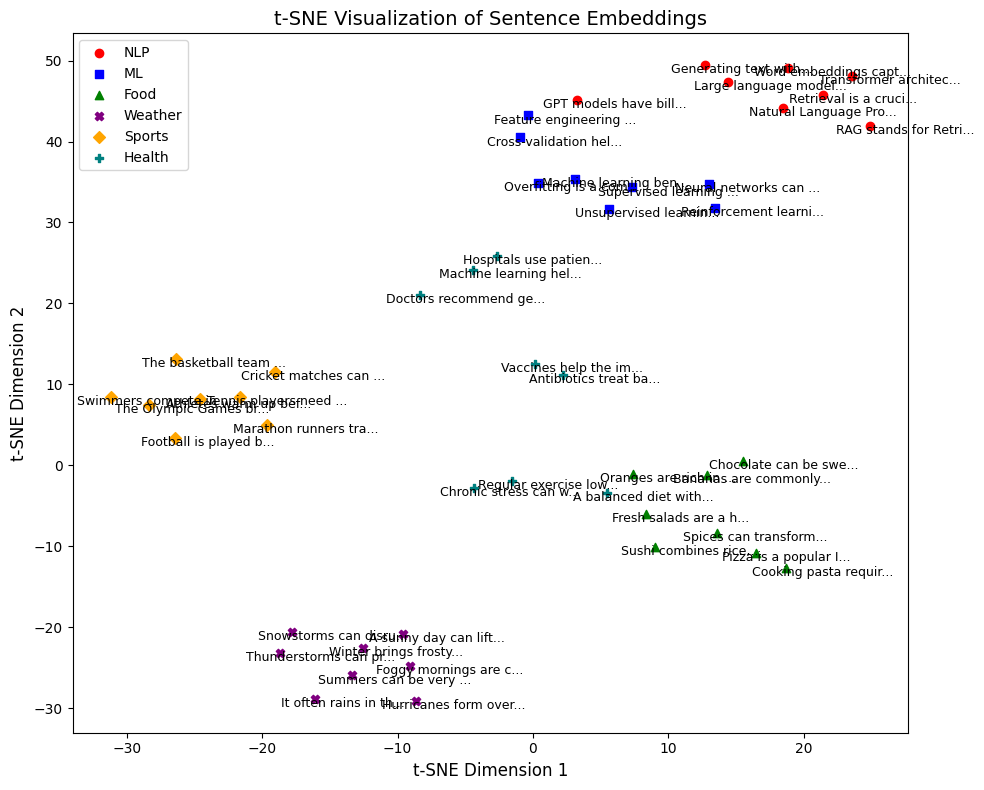

In [ ]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sentence_transformers import SentenceTransformer

def get_sentences_and_categories():
    """Return the sentences and their corresponding categories."""
    sentences = [
        # Topic: NLP
        "RAG stands for Retrieval-Augmented Generation.",
        "Retrieval is a crucial aspect of modern NLP systems.",
        "Generating text with correct facts is challenging.",
        "Large language models can generate coherent text.",
        "GPT models have billions of parameters.",
        "Natural Language Processing enables computers to understand human language.",
        "Word embeddings capture semantic relationships between words.",
        "Transformer architectures revolutionized NLP research.",

        # Topic: Machine Learning
        "Machine learning benefits from large datasets.",
        "Supervised learning requires labeled data.",
        "Reinforcement learning is inspired by behavioral psychology.",
        "Neural networks can learn complex functions.",
        "Overfitting is a common problem in ML.",
        "Unsupervised learning uncovers hidden patterns in data.",
        "Feature engineering is critical for model performance.",
        "Cross-validation helps in assessing model generalization.",

        # Topic: Food
        "Bananas are commonly used in smoothies.",
        "Oranges are rich in vitamin C.",
        "Pizza is a popular Italian dish.",
        "Cooking pasta requires boiling water.",
        "Chocolate can be sweet or bitter.",
        "Fresh salads are a healthy and refreshing meal.",
        "Sushi combines rice, fish, and seaweed in a delicate balance.",
        "Spices can transform simple ingredients into gourmet dishes.",

        # Topic: Weather
        "It often rains in the Amazon rainforest.",
        "Summers can be very hot in the desert.",
        "Hurricanes form over warm ocean waters.",
        "Snowstorms can disrupt transportation.",
        "A sunny day can lift people's mood.",
        "Foggy mornings are common in coastal regions.",
        "Winter brings frosty nights and chilly winds.",
        "Thunderstorms can produce lightning and heavy rain.",

        # Topic: Sports
        "Football is played by two teams of eleven players.",
        "Marathon runners train for months to build endurance.",
        "The basketball team won the championship in overtime.",
        "Tennis players need quick reflexes and strong stamina.",
        "Swimmers compete in freestyle, butterfly, and backstroke events.",
        "Cricket matches can last for several days.",
        "Athletes warm up before a game to prevent injuries.",
        "The Olympic Games bring together athletes from around the world.",

        # Topic: Health
        "Regular exercise lowers the risk of heart disease.",
        "Doctors recommend getting at least seven hours of sleep.",
        "Vaccines help the immune system fight infections.",
        "A balanced diet with enough vitamins supports good health.",
        "Machine learning helps doctors detect diseases early.",
        "Hospitals use patient data to predict treatment outcomes.",
        "Chronic stress can weaken the body over time.",
        "Antibiotics treat bacterial infections but not viruses.",
    ]

    categories = (
        ["NLP"] * 8
        + ["ML"] * 8
        + ["Food"] * 8
        + ["Weather"] * 8
        + ["Sports"] * 8
        + ["Health"] * 8
    )
    assert len(sentences) == len(categories), "Sentences and categories must match in length"
    return sentences, categories


def get_color_and_shape_maps():
    """Return color and marker maps for each category."""
    color_map = {
        "NLP": "red",
        "ML": "blue",
        "Food": "green",
        "Weather": "purple",
        "Sports": "orange",
        "Health": "teal",
    }
    shape_map = {
        "NLP": "o",
        "ML": "s",
        "Food": "^",
        "Weather": "X",
        "Sports": "D",
        "Health": "P",
    }
    return color_map, shape_map

def compute_tsne_embeddings(sentences, model_name="sentence-transformers/all-MiniLM-L6-v2",
                              perplexity=6, max_iter=3000, random_state=42):
    """Compute and return t-SNE reduced embeddings for the given sentences."""
    model = SentenceTransformer(model_name)
    embeddings = model.encode(sentences)
    tsne = TSNE(n_components=2, random_state=random_state,
                perplexity=perplexity, max_iter=max_iter)
    return tsne.fit_transform(embeddings)

def plot_embeddings(reduced_embeddings, sentences, categories, color_map, shape_map):
    """Plot the 2D embeddings with labels and a legend."""
    plt.figure(figsize=(10, 8))
    for i, (sentence, category) in enumerate(zip(sentences, categories)):
        x, y = reduced_embeddings[i]
        plt.scatter(x, y, color=color_map[category], marker=shape_map[category])
        plt.text(x - 2.5, y - 1.0, sentence[:20] + "...", fontsize=9)

    for cat, color in color_map.items():
        plt.scatter([], [], color=color, label=cat, marker=shape_map[cat])
    plt.legend(loc="best")

    plt.title("t-SNE Visualization of Sentence Embeddings", fontsize=14)
    plt.xlabel("t-SNE Dimension 1", fontsize=12)
    plt.ylabel("t-SNE Dimension 2", fontsize=12)
    plt.tight_layout()
    plt.savefig('t-SNE-6-categories-embeddings-plot.png')

sentences, categories = get_sentences_and_categories()
color_map, shape_map = get_color_and_shape_maps()
reduced_embeddings = compute_tsne_embeddings(sentences)
plot_embeddings(reduced_embeddings, sentences, categories, color_map, shape_map)

## Conclusion and Next Steps

You've now seen how to represent text data with embeddings, reduce those embeddings to reveal a simpler underlying structure, and visualize them to uncover meaningful relationships.

Equipped with this knowledge, you can now create plots where related sentences cluster closely, confirming that embeddings capture meaningful relationships. This visualization is often quite revealing when debugging or exploring text data.

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# Comparing Bag-of-Words and Embeddings-Based Semantic Search

## Introduction

Welcome to our final lesson in this course about **Text Representation Techniques for RAG Systems**! You’ve already explored the basics of **Bag-of-Words (BOW)** representations and experimented with **sentence embeddings** in earlier lessons. Now, we’re going to compare how these two methods differ in actual search scenarios. Think of this as a practical refresher on BOW and embeddings, but with an added focus on side-by-side comparison and deciding which approach might be best for different retrieval use cases.

## From Words To Meaning: Why We Need Both Approaches

Before diving into the code, let’s clarify why both methods — from straightforward word matching to deeper semantic modeling — are valuable.

* **Lexical Overlap (BOW)**: This approach checks for exact word matches, making it easy to interpret how documents are scored. If your query has the phrase "external data," any document containing those exact words gets a higher score. It’s simple, transparent, and efficient for many tasks. But BOW can struggle with synonyms or varying phrasing.

* **Semantic Similarity (Embeddings)**: Here, we focus on the overall meaning rather than specific words. Two differently phrased sentences can still be close in the embedding space if they convey the same idea. This approach excels at capturing nuances. However, it depends on a trained model and requires more computation.

In some real-world settings, you might even combine both: run a quick lexical match and then refine the results with a more precise semantic model. Let’s see how these methods look in code so you can start comparing results for yourself.

## Implementing Bag-of-Words Search

Below is an example of how to implement a BOW-based search workflow. We first build a vocabulary, then vectorize each document and the query according to how often each word appears.

In [ ]:
def bow_vectorize(text, vocab):
    """
    Convert a text into a Bag-of-Words vector by counting how many times
    each token from our vocabulary appears in the text.
    """
    vector = np.zeros(len(vocab), dtype=int)
    for word in text.lower().split():
        # Remove punctuation for consistency
        clean_word = word.strip(".,?!")
        if clean_word in vocab:
            vector[vocab[clean_word]] += 1
    return vector

def bow_search(query, docs):
    """
    Rank documents by lexical overlap using the BOW technique.
    The dot product between the query vector and each document vector
    indicates how many words they share.
    """
    query_vector = bow_vectorize(query, VOCAB)
    scores = []
    for i, doc in enumerate(docs):
        doc_vector = bow_vectorize(doc, VOCAB)
        score = np.dot(query_vector, doc_vector)  # Higher score => more overlap
        scores.append((i, score))

    # Sort by descending overlap
    scores.sort(key=lambda x: x[1], reverse=True)
    return scores

Let's break this down:

* `bow_vectorize`: Splits the text into words, applies some light cleanup (punctuation removal), and counts occurrences. If “external” appears once in the query, that contributes 1 to the corresponding position in the query vector.
* `bow_search`: Converts the query into a BOW vector, does the same for each document, and uses the dot product to measure shared token counts. Documents with many overlapping terms move to the top of the list.

This method is straightforward and fast for situations when exact word usage is critical. But what if your query is phrased differently than the document’s text? That’s where embeddings shine.

## Implementing Embedding-based Search

To tackle the challenge of phrasing differences or synonyms, let’s look at embedding-based search:

In [ ]:
def cosine_similarity(vec_a, vec_b):
    """
    Compute cosine similarity between two vectors,
    indicating how similar they are.
    """
    return np.dot(vec_a, vec_b) / (norm(vec_a) * norm(vec_b))

def embedding_search(query, docs, model):
    """
    Rank documents by comparing how semantically close they are
    to the query in the embedding space using cosine similarity.
    """
    # Encode both the query and documents into embeddings
    query_embedding = model.encode([query])[0]
    doc_embeddings = model.encode(docs)

    scores = []
    for i, doc_embedding in enumerate(doc_embeddings):
        similarity_score = cosine_similarity(query_embedding, doc_embedding)
        scores.append((i, similarity_score))

    # Sort by semantic similarity in descending order
    scores.sort(key=lambda x: x[1], reverse=True)
    return scores

In this code snippet:

* `cosine_similarity`: Implement cosine similarity function to measure how closely two vectors align. Remember, if they point in a similar direction in embedding space, the cosine similarity value is higher.
* `embedding_search`: Converts the query and each document into embedding vectors using the model, then uses cosine similarity to rank how “close” the document is to the query’s meaning.

Here, the retrieval process depends more on interpretive meaning than precise word matching. That means a query about “combining external data with generative models” can find documents discussing “merging external text into RAG systems,” even if some words differ.

## Bag-of-Words Search vs Embedding-based Search

In [ ]:
import numpy as np
from numpy.linalg import norm
from sentence_transformers import SentenceTransformer

KNOWLEDGE_BASE = [
    "Retrieval-Augmented Generation (RAG) enhances language models by integrating relevant external documents into the generation process.",
    "RAG systems retrieve information from large databases to provide contextual answers beyond what is stored in the model.",
    "By merging retrieved text with generative models, RAG overcomes the limitations of static training data.",
    "Media companies combine external data feeds with digital editing tools to optimize broadcast schedules.",
    "Financial institutions analyze market data and use automated report generation to guide investment decisions.",
    "Healthcare analytics platforms integrate patient records with predictive models to generate personalized care plans.",
    "Bananas are popular fruits that are rich in essential nutrients such as potassium and vitamin C."
]

def build_vocab(docs):
    """
    Dynamically build a vocabulary from the given docs.
    Each new word in the corpus is an entry in the vocabulary.
    """
    unique_words = set()
    for doc in docs:
        for word in doc.lower().split():
            clean_word = word.strip(".,!?")
            if clean_word:
                unique_words.add(clean_word)
    return {word: idx for idx, word in enumerate(sorted(unique_words))}

VOCAB = build_vocab(KNOWLEDGE_BASE)

query = "How does a system combine external data with language generation to improve responses?"
print(f"Query: {query}")

model_name = "sentence-transformers/all-MiniLM-L6-v2"
model = SentenceTransformer(model_name)

# BOW-based search
bow_results = bow_search(query, KNOWLEDGE_BASE)
print("\nBOW Search Results:")
for idx, score in bow_results:
    print(f"  Doc {idx} | Score: {score} | Text: {KNOWLEDGE_BASE[idx]}")

# Embedding-based search
embedding_results = embedding_search(query, KNOWLEDGE_BASE, model)
print("\nEmbedding-based Search Results:")
for idx, score in embedding_results:
    print(f"  Doc {idx} | Score: {score} | Text: {KNOWLEDGE_BASE[idx]}")

Query: How does a system combine external data with language generation to improve responses?

BOW Search Results:
  Doc 3 | Score: 5 | Text: Media companies combine external data feeds with digital editing tools to optimize broadcast schedules.
  Doc 0 | Score: 4 | Text: Retrieval-Augmented Generation (RAG) enhances language models by integrating relevant external documents into the generation process.
  Doc 4 | Score: 3 | Text: Financial institutions analyze market data and use automated report generation to guide investment decisions.
  Doc 2 | Score: 2 | Text: By merging retrieved text with generative models, RAG overcomes the limitations of static training data.
  Doc 5 | Score: 2 | Text: Healthcare analytics platforms integrate patient records with predictive models to generate personalized care plans.
  Doc 1 | Score: 1 | Text: RAG systems retrieve information from large databases to provide contextual answers beyond what is stored in the model.
  Doc 6 | Score: 0 | Text: Banana

## Analyzing the Search Output

Finally, let's consider the sample query `"How does a system combine external data with language generation to improve responses?"` and discuss the corresponding search results for both Bag-of-Words (BOW) and embedding-based methods:

```plaintext
Query: How does a system combine external data with language generation to improve responses?

BOW Search Results:
  Doc 3 | Score: 5 | Text: Media companies combine external data feeds with digital editing tools to optimize broadcast schedules.
  Doc 0 | Score: 4 | Text: Retrieval-Augmented Generation (RAG) enhances language models by integrating relevant external documents into the generation process.
  Doc 4 | Score: 3 | Text: Financial institutions analyze market data and use automated report generation to guide investment decisions.
  Doc 2 | Score: 2 | Text: By merging retrieved text with generative models, RAG overcomes the limitations of static training data.
  Doc 5 | Score: 2 | Text: Healthcare analytics platforms integrate patient records with predictive models to generate personalized care plans.
  Doc 1 | Score: 1 | Text: RAG systems retrieve information from large databases to provide contextual answers beyond what is stored in the model.
  Doc 6 | Score: 0 | Text: Bananas are popular fruits that are rich in essential nutrients such as potassium and vitamin C.

Embedding-based Search Results:
  Doc 0 | Score: 0.5939 | Text: Retrieval-Augmented Generation (RAG) enhances language models by integrating relevant external documents into the generation process.
  Doc 1 | Score: 0.4375 | Text: RAG systems retrieve information from large databases to provide contextual answers beyond what is stored in the model.
  Doc 2 | Score: 0.4234 | Text: By merging retrieved text with generative models, RAG overcomes the limitations of static training data.
  Doc 3 | Score: 0.3179 | Text: Media companies combine external data feeds with digital editing tools to optimize broadcast schedules.
  Doc 4 | Score: 0.2539 | Text: Financial institutions analyze market data and use automated report generation to guide investment decisions.
  Doc 5 | Score: 0.2015 | Text: Healthcare analytics platforms integrate patient records with predictive models to generate personalized care plans.
  Doc 6 | Score: 0.0802 | Text: Bananas are popular fruits that are rich in essential nutrients such as potassium and vitamin C.
```

When using BOW, notice that the ranking primarily hinges on exact keyword matches. For instance, Document 3 is placed at the top solely because the text explicitly contains the words “combine” and “external,” even though Document 0 is arguably more relevant to the query’s intent regarding language models and RAG. Meanwhile, the embedding-based approach ranks Document 0 higher because it captures the semantic relationship between “language generation” and “integrating relevant external documents,” even though some of the words do not match exactly.

By contrast, embeddings allow for more flexibility and deeper understanding, helping it correctly elevate items like Document 0 and Document 1, which are more relevant to the query’s goal, above Document 3. This further illustrates how embeddings can bridge the gap when different but related terms appear in the query and the documents.

## Enhance Bag-of-Words with Bigrams

Let's enhance the Bag-of-Words approach by incorporating bigrams into the `bow_vectorize` function.

Bigrams are a type of *N-grams*, which are contiguous sequences of `n` items from a given text. In the case of bigrams, `n` is `2`, meaning each bigram consists of two consecutive words; for example, in the sentence `"RAG systems retrieve information"` the bigrams are `"RAG systems"`, `"systems retrieve"`, and `"retrieve information"`.

Your tasks are to:

* Modify `build_vocab` to include bigrams. This means that for each document, you should extract both individual words and pairs of consecutive words (bigrams) to add to the vocabulary. Form bigrams only from the cleaned words: after stripping punctuation, drop any token that becomes empty (such as `"..."` or `"?!"`) before pairing, so `"Hello ... there."` yields the tokens `hello`, `there`, and `hello there`, and never a token with a leading or trailing space.
* Update `bow_vectorize` to count bigrams. When vectorizing a text, ensure that both unigrams (single words) and bigrams are counted and represented in the vector.
* Integrate these changes into the `bow_search` function. This will allow the search to consider both individual words and word pairs, potentially improving the relevance of document rankings.

By incorporating bigrams, you'll be able to capture more context from the text, which can lead to more accurate search results. Dive in and explore the impact of bigrams on search results!

In [ ]:
import numpy as np
from numpy.linalg import norm
from sentence_transformers import SentenceTransformer

KNOWLEDGE_BASE = [
    "Retrieval-Augmented Generation (RAG) enhances language models by integrating relevant external documents into the generation process.",
    "RAG systems retrieve information from large databases to provide contextual answers beyond what is stored in the model.",
    "By merging retrieved text with generative models, RAG overcomes the limitations of static training data.",
    "Media companies combine external data feeds with digital editing tools to optimize broadcast schedules.",
    "Financial institutions analyze market data and use automated report generation to guide investment decisions.",
    "Healthcare analytics platforms integrate patient records with predictive models to generate personalized care plans.",
    "Bananas are popular fruits that are rich in essential nutrients such as potassium and vitamin C."
]


def build_vocab(docs):
    """
    Dynamically build a vocabulary from the given docs.
    Each new word or bigram in the corpus is an entry in the vocabulary.
    """
    unique_tokens = set()
    for doc in docs:
        # Strip punctuation and drop tokens that become empty (e.g. "..." or "?!")
        words = [w for w in (word.strip(".,!?") for word in doc.lower().split()) if w]
        for i in range(len(words)):
            unique_tokens.add(words[i])
            # TODO: Add bigrams to the vocabulary
            if i < len(words) - 1:
                bigram = ' '.join([words[i], words[i+1]])
                unique_tokens.add(bigram)
    return {token: idx for idx, token in enumerate(sorted(unique_tokens))}


VOCAB = build_vocab(KNOWLEDGE_BASE)


def bow_vectorize(text, vocab=VOCAB):
    """
    Convert a text into a Bag-of-Words vector, using a shared vocabulary.
    Each element counts how many times a particular token or bigram appears.
    """
    vector = np.zeros(len(vocab), dtype=int)
    words = [w for w in (word.strip(".,!?") for word in text.lower().split()) if w]
    for i in range(len(words)):
        if words[i] in vocab:
            vector[vocab[words[i]]] += 1
        # TODO: Count bigrams in the vector
        if i < len(words) - 1:
            bigram = ' '.join([words[i], words[i+1]])
            if bigram in vocab:
                vector[vocab[bigram]] += 1
    return vector


def bow_search(query, docs):
    """
    Rank documents by lexical overlap (BOW) using unigrams and bigrams.
    The dot product between query and doc vectors reflects how many
    tokens they have in common.
    """
    query_vec = bow_vectorize(query)
    scores = []
    for i, doc in enumerate(docs):
        doc_vec = bow_vectorize(doc)
        score = np.dot(query_vec, doc_vec)
        scores.append((i, score))
    # Sort documents so that higher lexical overlap is first
    scores.sort(key=lambda x: x[1], reverse=True)
    return scores


query = "How does a system combine external data with language generation to improve responses?"
print(f"Query: {query}")

print(f"\nVocabulary: {VOCAB}")

# BOW-based search
bow_results = bow_search(query, KNOWLEDGE_BASE)
print("\nBOW Search Results:")
for idx, score in bow_results:
    print(f"  Doc {idx} | Score: {score} | Text: {KNOWLEDGE_BASE[idx]}")


Query: How does a system combine external data with language generation to improve responses?

Vocabulary: {'(rag)': 0, '(rag) enhances': 1, 'analytics': 2, 'analytics platforms': 3, 'analyze': 4, 'analyze market': 5, 'and': 6, 'and use': 7, 'and vitamin': 8, 'answers': 9, 'answers beyond': 10, 'are': 11, 'are popular': 12, 'are rich': 13, 'as': 14, 'as potassium': 15, 'automated': 16, 'automated report': 17, 'bananas': 18, 'bananas are': 19, 'beyond': 20, 'beyond what': 21, 'broadcast': 22, 'broadcast schedules': 23, 'by': 24, 'by integrating': 25, 'by merging': 26, 'c': 27, 'care': 28, 'care plans': 29, 'combine': 30, 'combine external': 31, 'companies': 32, 'companies combine': 33, 'contextual': 34, 'contextual answers': 35, 'data': 36, 'data and': 37, 'data feeds': 38, 'databases': 39, 'databases to': 40, 'decisions': 41, 'digital': 42, 'digital editing': 43, 'documents': 44, 'documents into': 45, 'editing': 46, 'editing tools': 47, 'enhances': 48, 'enhances language': 49, 'essenti

## Conclusion and Next Steps

In this lesson, we compared a **Bag-of-Words-based search** with **embedding-based semantic search** and saw how each method ranks documents differently. BOW is agile for quick, vocabulary-based matches, while embeddings capture deeper connections between words and phrases.

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# References

- **[CodeSignal: Text Representation Techniques for RAG Systems Course](https://codesignal.com/learn/courses/text-representation-techniques-for-rag-systems)**

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)